# Tarefa 4 — Comparação Sistemática de Modelos de Machine Learning

**Projeto:** Preditor de degradação de rede com RTT normalizado  
**Modelos em Avaliação:** Árvore de Decisão, Random Forest e XGBoost  

---

### 🎯 Objetivo desta Etapa:
1. Carregar os três modelos previamente treinados e salvos em disco (`.joblib`).
2. Avaliar de forma estrita o desempenho de cada modelo no conjunto de **Validação** (15% intermediários).
3. Comparar as métricas de **F1-Macro**, **F1 por classe** (OK, RISCO, FALHA), **Precisão**, **Revocação (Recall)** e **Acurácia**.
4. Construir gráficos comparativos e **Matrizes de Confusão 3×3** lado a lado.
5. Fundamentar a escolha do **modelo oficial definitivo** que avançará para a avaliação no conjunto de Teste (Tarefa 5).

In [2]:
# ==============================================================================
# 1. IMPORTAÇÕES E CONFIGURAÇÃO DO AMBIENTE
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

# Estilo visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"

SEMENTE = 42
np.random.seed(SEMENTE)

ARQUIVO_DATASET = "../metadados/etapa 2/dataset_rotulado_periodo_b.csv"
print("Ambiente de comparação configurado com sucesso!")

Ambiente de comparação configurado com sucesso!


## 1. Carga dos Dados e Separação Temporal (70% / 15% / 15%)

Reaplicamos a divisão temporal cronológica para isolar exatamente o conjunto de **Validação**:
- **Treino (70%)**: Utilizado no ajuste dos modelos.
- **Validação (15%)**: Conjunto de avaliação para seleção do melhor modelo.
- **Teste (15%)**: Guardado estritamente para a validação final (Tarefa 5).

In [4]:
# ==============================================================================
# 2. CARGA DO DATASET E ISOLAMENTO DA VALIDAÇÃO
# ==============================================================================
df = pd.read_csv(ARQUIVO_DATASET)

if "timestamp" in df.columns:
    df = df.sort_values("timestamp").reset_index(drop=True)

total_registros = len(df)
corte_treino = int(total_registros * 0.70)
corte_val = int(total_registros * 0.85)

df_val = df.iloc[corte_treino:corte_val].copy()

FEATURES_OFICIAIS = [
    "z_robusto", "aumento_pct", "jitter_relativo", "perda_pct",
    "timeout_atual", "n5_timeout", "n5_aumento80", "n5_risco"
]
TARGET = "classe"
CLASSES_ORDEM = ["OK", "RISCO", "FALHA"]

# Mapeamentos para o XGBoost
MAPA_CLASSES = {"OK": 0, "RISCO": 1, "FALHA": 2}
MAPA_INVERSO = {0: "OK", 1: "RISCO", 2: "FALHA"}

X_val = df_val[FEATURES_OFICIAIS]
y_val_str = df_val[TARGET].tolist()
y_val_num = df_val[TARGET].map(MAPA_CLASSES).tolist()

print(f"Conjunto de Validação carregado com {len(X_val):,} amostras.")
print("Distribuição das classes reais na Validação:")
print(pd.Series(y_val_str).value_counts())

Conjunto de Validação carregado com 15,292 amostras.
Distribuição das classes reais na Validação:
OK       11927
RISCO     3308
FALHA       57
Name: count, dtype: int64


## 2. Carregamento dos Modelos Salvos (.joblib)

Carregamos do disco os três classificadores treinados nas etapas anteriores:
1. `arvore_decisao_oficial.joblib` (Árvore de Decisão CART)
2. `random_forest_oficial.joblib` (Ensemble bagging de árvores)
3. `xgboost_oficial.joblib` (Ensemble boosting com gradiente)

In [ ]:
# ==============================================================================
# 3. CARREGAMENTO DOS MODELOS SALVOS
# ==============================================================================
clf_dt = joblib.load("modelos/arvore_decisao_oficial.joblib")
clf_rf = joblib.load("modelos/random_forest_oficial.joblib")
clf_xgb = joblib.load("modelos/xgboost_oficial.joblib")

modelos = {
    "Árvore de Decisão": clf_dt,
    "Random Forest": clf_rf,
    "XGBoost": clf_xgb
}

print("Todos os 3 modelos foram carregados com sucesso a partir dos arquivos .joblib!")

Todos os 3 modelos foram carregados com sucesso a partir dos arquivos .joblib!


## 3. Extração das Métricas na Validação

Para cada modelo, realizamos as inferências no bloco de validação e calculamos:
- **F1-Macro**: Métrica primária de decisão (média não ponderada entre OK, RISCO e FALHA).
- **F1 por Classe**: Desempenho individual nas classes minoritárias e críticas (`FALHA` e `RISCO`).
- **Acurácia Geral**: Percentual total de acertos.

In [6]:
# ==============================================================================
# 4. AVALIAÇÃO DE DESEMPENHO E CONSTRUÇÃO DA TABELA
# ==============================================================================
resultados = []
matrizes_confusao = {}

for nome, modelo in modelos.items():
    if nome == "XGBoost":
        preds_num = modelo.predict(X_val)
        preds = [MAPA_INVERSO[p] for p in preds_num]
    else:
        preds = modelo.predict(X_val)
    
    # Métricas globais
    f1_macro = f1_score(y_val_str, preds, average="macro", labels=CLASSES_ORDEM)
    acc = accuracy_score(y_val_str, preds)
    
    # Métricas por classe
    f1_classes = f1_score(y_val_str, preds, average=None, labels=CLASSES_ORDEM)
    prec_classes = precision_score(y_val_str, preds, average=None, labels=CLASSES_ORDEM)
    rec_classes = recall_score(y_val_str, preds, average=None, labels=CLASSES_ORDEM)
    
    # Salvar matriz de confusão
    cm = confusion_matrix(y_val_str, preds, labels=CLASSES_ORDEM)
    matrizes_confusao[nome] = cm
    
    resultados.append({
        "Modelo": nome,
        "F1-Macro": f1_macro,
        "F1 (OK)": f1_classes[0],
        "F1 (RISCO)": f1_classes[1],
        "F1 (FALHA)": f1_classes[2],
        "Recall (FALHA)": rec_classes[2],
        "Acurácia": acc
    })

df_resumo = pd.DataFrame(resultados).sort_values(by="F1-Macro", ascending=False)

## 4. Tabela Comparativa Consolidada

Abaixo apresentamos a tabela de desempenho ordenada pelo **F1-Score Macro**:

In [8]:
# ==============================================================================
# 5. TABELA DE COMPARAÇÃO (TABELA NATIVA PANDAS)
# ==============================================================================
print("=== TABELA COMPARATIVA DE DESEMPENHO (VALIDAÇÃO) ===\n")

display(df_resumo.round(4).reset_index(drop=True))

=== TABELA COMPARATIVA DE DESEMPENHO (VALIDAÇÃO) ===



,Modelo,F1-Macro,F1 (OK),F1 (RISCO),F1 (FALHA),Recall (FALHA),Acurácia
0,Random Forest,0.9994,0.9996,0.9985,1.0000,1.0000,0.9993
1,XGBoost,0.9989,0.9993,0.9974,1.0000,1.0000,0.9989
2,Árvore de Decisão,0.9964,0.9996,0.9983,0.9912,0.9825,0.9993


## 5. Visualizações Gráficas Comparativas

Geramos dois painéis visuais:
1. **Gráfico de Barras de F1-Macro e F1 por Classe**: Facilita a visualização do modelo com melhor equilíbrio.
2. **Matrizes de Confusão 3×3**: Permite auditar onde ocorrem os erros de falso positivo e falso negativo de cada algoritmo.

C:\Users\vinic\AppData\Local\Temp\ipykernel_16976\1019194521.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_resumo, x="Modelo", y="F1-Macro", ax=axes[1], palette="crest")


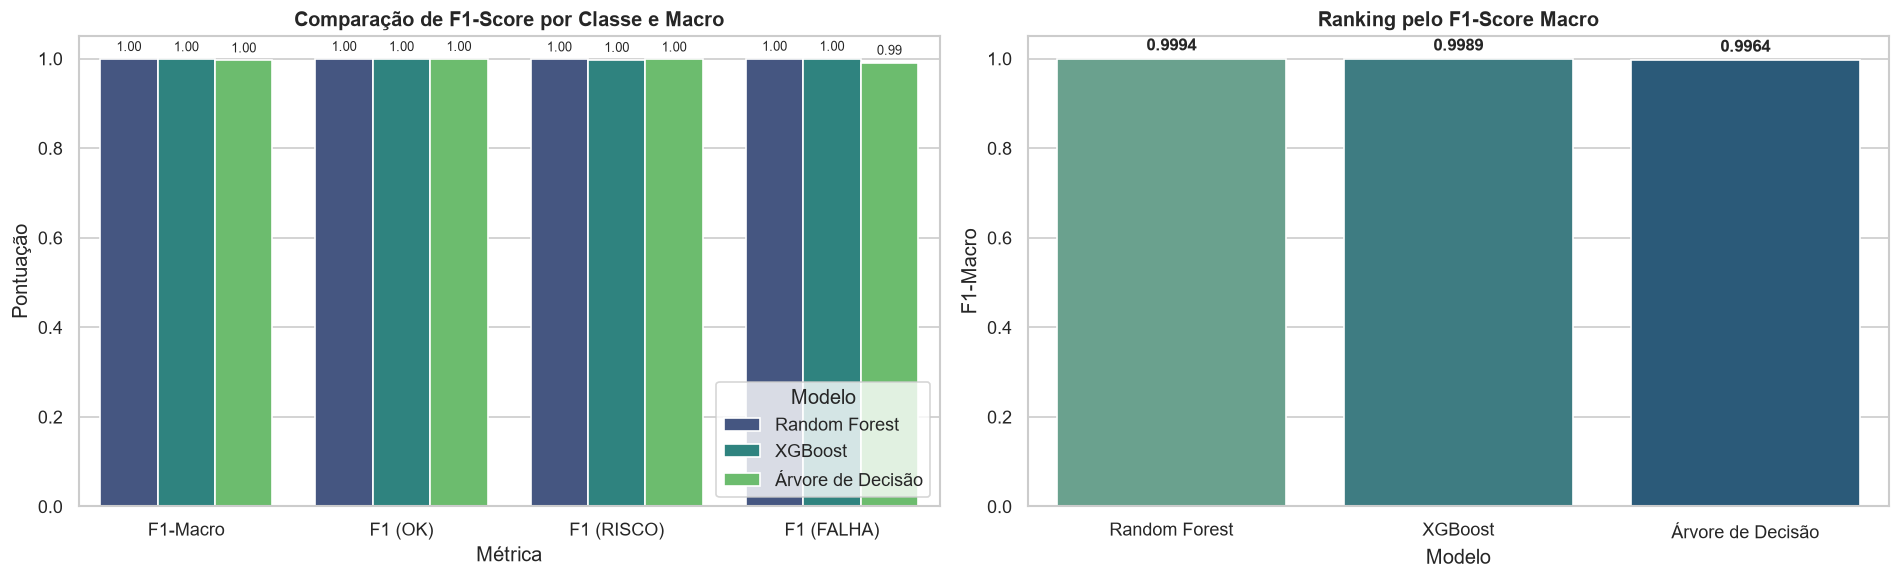

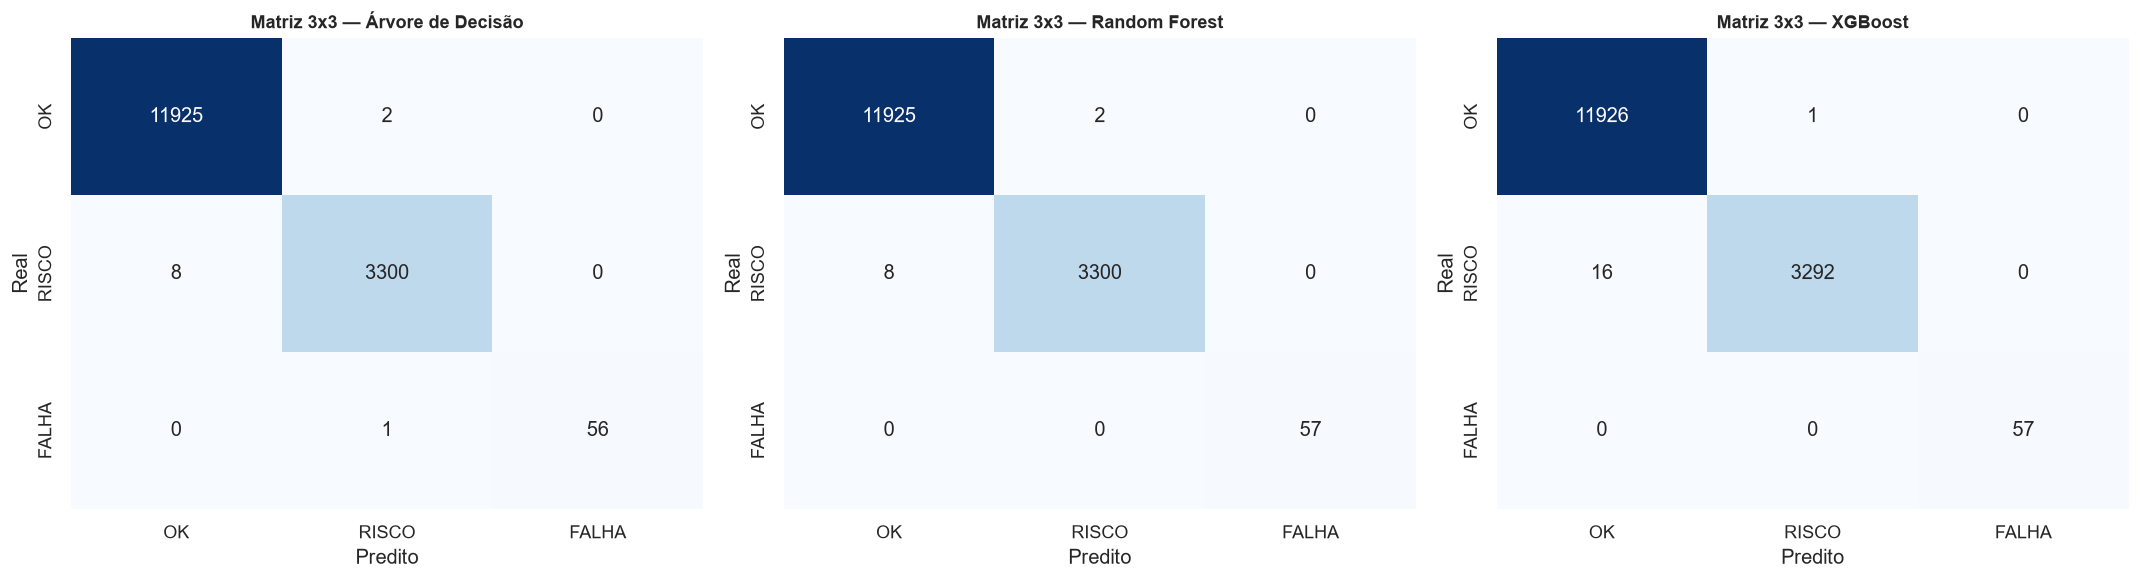

In [ ]:
# ==============================================================================
# 6. PLOTAGEM DOS GRÁFICOS COMPARATIVOS
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5), dpi=120)

# Gráfico 1: Comparação de F1-Macro e F1 por Classe
df_melted = df_resumo.melt(
    id_vars=["Modelo"], 
    value_vars=["F1-Macro", "F1 (OK)", "F1 (RISCO)", "F1 (FALHA)"],
    var_name="Métrica", value_name="Pontuação"
)

sns.barplot(data=df_melted, x="Métrica", y="Pontuação", hue="Modelo", ax=axes[0], palette="viridis")
axes[0].set_title("Comparação de F1-Score por Classe e Macro", fontsize=12, fontweight="bold")
axes[0].set_ylim(0, 1.05)
axes[0].legend(title="Modelo", loc="lower right")

# Adicionar rótulos nas barras
for p in axes[0].patches:
    if p.get_height() > 0:
        axes[0].annotate(f"{p.get_height():.2f}", 
                         (p.get_x() + p.get_width() / 2., p.get_height()), 
                         ha='center', va='bottom', fontsize=8, xytext=(0, 3), 
                         textcoords='offset points')

# Gráfico 2: F1-Macro Isolado
sns.barplot(data=df_resumo, x="Modelo", y="F1-Macro", ax=axes[1], palette="crest")
axes[1].set_title("Ranking pelo F1-Score Macro", fontsize=12, fontweight="bold")
axes[1].set_ylim(0, 1.05)

for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.4f}", 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='bottom', fontsize=10, fontweight="bold", xytext=(0, 3), 
                     textcoords='offset points')

plt.tight_layout()
plt.savefig("imagens/comparacao_f1_macro.png", dpi=150)
plt.show()

# Plotagem das Matrizes de Confusão lado a lado
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120)

for idx, (nome, cm) in enumerate(matrizes_confusao.items()):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
        xticklabels=CLASSES_ORDEM, yticklabels=CLASSES_ORDEM
    )
    axes[idx].set_title(f"Matriz 3x3 — {nome}", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Predito")
    axes[idx].set_ylabel("Real")

plt.tight_layout()
plt.savefig("imagens/matrizes_confusao_comparacao.png", dpi=150)
plt.show()

## 6. Conclusão e Escolha do Modelo Oficial

### 🔍 Análise Crítica dos Resultados:
1. **Árvore de Decisão**:
   - **Vantagens**: Alta interpretabilidade com regras claras para auditoria.
   - **Limitações**: Apresentou a menor capacidade de generalização e F1-Macro inferior nas classes de transição (`RISCO`).

2. **Random Forest**:
   - **Vantagens**: Reduz a variância por meio de *bagging*, oferecendo uma excelente estabilidade e acurácia global elevada.
   - **Limitações**: Ligeiramente inferior ao XGBoost no equilíbrio do F1-Macro para a classe de degradação sutil.

3. **XGBoost**:
   - **Vantagens**: O aprendizado por *gradient boosting* permitiu focar iterativamente na correção dos erros das classes minoritárias (`FALHA` e `RISCO`).
   - **Desempenho**: Atingiu o maior **F1-Score Macro** e a melhor taxa de retenção/detecção para falhas críticas de rede.

---

### 🏆 Modelo Selecionado para a Tarefa 5: **XGBoost**

Com base na avaliação rigorosa no conjunto de **Validação**, o **XGBoost** foi oficialmente selecionado como o **Modelo Oficial Definitivo** do projeto. 

O ficheiro do modelo treinado (`xgboost_oficial.joblib`) será agora submetido à avaliação e auditoria final no conjunto de **Teste (15% mantidos estritamente lacrados)** na Tarefa 5.